# PROYECTO INTEGRADO SPRINT 13

Análisis de proceso de extracción y purificación de oro

## 1. Preparación de los datos

### 1.1 Descarga y evaluación de los datos

In [1]:
# Descarga librerias requeridas
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, make_scorer

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Lectura de archivos
autrain = pd.read_csv('/datasets/gold_recovery_train.csv')
autest = pd.read_csv('/datasets/gold_recovery_test.csv')
aufull = pd.read_csv('/datasets/gold_recovery_full.csv')

# Revisión de archivos: 
print('Forma general del archivo de entrenamiento (filas, columnas): ', autrain.shape)
print()
print('Forma general del archivo de prueba (filas, columnas): ', autest.shape)
print()
print('Forma general del archivo inicial (filas, columnas): ', aufull.shape)
print()

print('Información general de los archivos:')
print('autrain')
autrain.info() 
print()
print('autest1')
autest.info() 
print()
print('aufull')
aufull.info() 
print()

print('Vista de las primeras 10 filas de los archivos:')
print('autrain')
print(autrain.head(10))
print()
print('autest')
print(autest.head(10))
print()
print('aufull')
print(aufull.head(10))
print()

print('Datos duplicados en archivos:')
print('autrain: ', autrain.duplicated().sum())
print()
print('autest: ', autest.duplicated().sum())
print()
print('aufull: ', aufull.duplicated().sum())
print()

print('Estadística descriptiva de los archivos:')
print('autrain')
print(autrain.describe())
print()
print('autest')
print(autest.describe())
print()
print('aufull')
print(aufull.describe())
print()


Forma general del archivo de entrenamiento (filas, columnas):  (16860, 87)

Forma general del archivo de prueba (filas, columnas):  (5856, 53)

Forma general del archivo inicial (filas, columnas):  (22716, 87)

Información general de los archivos:
autrain
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16860 entries, 0 to 16859
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   date                                                16860 non-null  object 
 1   final.output.concentrate_ag                         16788 non-null  float64
 2   final.output.concentrate_pb                         16788 non-null  float64
 3   final.output.concentrate_sol                        16490 non-null  float64
 4   final.output.concentrate_au                         16789 non-null  float64
 5   final.output.recovery                               15339 non-n

### Observaciones

1. Sobre la forma general de los archivos:
- autrain contiene 16860 registros en 87 columnas.
- autest contiene 5856 registros en 53 columnas.
- aufull contiene 22716 registros en 87 columnas.

que el archivo de prueba tenga solo 53 columnas indica que se realiza una depuración inicial de los datos. 

2. Sobre la información general de los datos:
- los 3 archivos presentan varios valores ausentes. Esto se puede deber a la posibilidad de que algunas concentraciones sean despreciables o a errores en la medición al momento de tomar los datos. Esto hará que se requiera un tratamiento especial de preprocesamiento antes de trabajar con los datos.
- Al revisar el nombre de las columnas de los archivos se encuentra que el archivo de prueba no incluye variables de salida de ninguna de las etapas de proceso y tiene un mayor enfasis en los datos de la etapa como tal, flujo de aire o nivel de los equipos de filtración. Esto puede llegar a afectar el cálculo de las recuperaciones, por lo que habría que revisar la importancia de utilizar este juego de datos en los entrenamientos.
- La columna de fecha 'date' se encuentra como tipo object, posiblemente se deba modificar en el preprocesamiento a tipo datetime.

3. Sobre la vista general de los datos:
- En los 3 juegos de datos se observa que las características presentan datos con valores variados en magnitud, esto hará que se requiera una normalización o escalado de las características a la hora de entrenar los modelos.

4. Revisión de duplicados:
- Ninguno de los 3 archivos presenta duplicados. No se requiere este tratamiento adicional a los datos.

5. Sobre las estadísticas descriptivas:
- De manera general, se observa amplia variabilidad de los datos para cada característica, esto se corrobora por los datos de desviación estándar y su comparación con los promedios aritméticos para cada característica. Esto afectará eventualmente las métricas de evaluación que se implementen.
  

### 1.2 Cálculo recuperación


In [2]:
# Definición de la función
def recovery (concentrate, feed, tails):
    rec = (concentrate *(feed - tails))/(feed * (concentrate - tails))
    recovery = rec * 100
    return recovery

# Aplicación de la función para el cálculo de la recuperación de la etapa Rougher
rougher_recovery = recovery(autrain['rougher.output.concentrate_au'], autrain['rougher.input.feed_au'], autrain['rougher.output.tail_au'])
print(rougher_recovery)

# Creación DataFrame con recuperaciones eliminando valores infinitos y Nan
rougher_recovery = pd.DataFrame({'recovery_calculated': rougher_recovery, 'recovery_autrain': autrain['rougher.output.recovery']}).replace([np.inf, -np.inf], np.nan).dropna()

# Cálculo del error absoluto medio entre los datos calculados y los presentes en el archivo
recovery_eam = mean_absolute_error(rougher_recovery['recovery_calculated'], rougher_recovery['recovery_autrain'])
print('El EAM del valor de recuperación rougher es: ', recovery_eam)

0        87.107763
1        86.843261
2        86.842308
3        87.226430
4        86.688794
           ...    
16855    89.574376
16856    87.724007
16857    88.890579
16858    89.858126
16859    89.514960
Length: 16860, dtype: float64
El EAM del valor de recuperación rougher es:  9.303415616264301e-15


### Observaciones
Al realizar el cálculo de la recuperación, y compararla con el valor que se tiene en los archivos, se encuentra que el error absoluto medio es de 9.3x10-15, un valor demasiado bajo, por lo que se puede suponer que la recuperación de esta etapa esta bien calculada en el archivo de entrenamiento.

### 1.3 Características faltantes en archivo de prueba

In [3]:

missing_columns_autest = sorted(set(autrain.columns) - set(autest.columns))
print(autrain[missing_columns_autest].dtypes)


final.output.concentrate_ag                           float64
final.output.concentrate_au                           float64
final.output.concentrate_pb                           float64
final.output.concentrate_sol                          float64
final.output.recovery                                 float64
final.output.tail_ag                                  float64
final.output.tail_au                                  float64
final.output.tail_pb                                  float64
final.output.tail_sol                                 float64
primary_cleaner.output.concentrate_ag                 float64
primary_cleaner.output.concentrate_au                 float64
primary_cleaner.output.concentrate_pb                 float64
primary_cleaner.output.concentrate_sol                float64
primary_cleaner.output.tail_ag                        float64
primary_cleaner.output.tail_au                        float64
primary_cleaner.output.tail_pb                        float64
primary_

### Observaciones
Al revisar las características ausentes en el conjunto de prueba se encuentra:
- En el conjunto de prueba no se tienen los valores de composición a las salidas de las etapas (.output), datos de calculo (.calculation) ni los calculos de las recuperaciones (.recovery). Estos datos son de tipo 'float64' en su totalidad.
- La ausencia de estas columnas es intencional y nos indica sobre que columnas debe entrenarse el modelo para prevenir la fuga de objetivos. Al momento de probar el modelo nos dará información sobre un escenario real operativo y evitará que el modelo entrenado quede con sesgos.


### 1.4 Preprocesamiento de datos

El preprocesamiento será el siguiente:
Archivo autrain:
- Cambio de formato columna 'date' de object a datetime.
- Retirar valores ausentes de todo el archivo.
- Quitar columnas que pueden sesgar el modelo (missing_columns_autest).

Archivo autest.
- Cambio de formato columna 'date' de tipo object a datetime.
- Retirar valores ausentes del archivo


In [4]:

# archivo autrain

# Cambio de formato en columna 'date'
autrain['date']= pd.to_datetime(autrain['date'])

# Retiro columnas que provocan sesgo en el entrenamiento del modelo
autrain_clean = autrain.drop(columns=missing_columns_autest)

# Retiro valores ausentes
autrain_clean = autrain_clean.dropna()

print(autrain_clean.info())


<class 'pandas.core.frame.DataFrame'>
Int64Index: 13522 entries, 0 to 16859
Data columns (total 53 columns):
 #   Column                                      Non-Null Count  Dtype         
---  ------                                      --------------  -----         
 0   date                                        13522 non-null  datetime64[ns]
 1   primary_cleaner.input.sulfate               13522 non-null  float64       
 2   primary_cleaner.input.depressant            13522 non-null  float64       
 3   primary_cleaner.input.feed_size             13522 non-null  float64       
 4   primary_cleaner.input.xanthate              13522 non-null  float64       
 5   primary_cleaner.state.floatbank8_a_air      13522 non-null  float64       
 6   primary_cleaner.state.floatbank8_a_level    13522 non-null  float64       
 7   primary_cleaner.state.floatbank8_b_air      13522 non-null  float64       
 8   primary_cleaner.state.floatbank8_b_level    13522 non-null  float64       
 9   primar

In [5]:

# archivo autest

# Cambio de formato en columna 'date'
autest['date']= pd.to_datetime(autest['date'])

# Retiro valores ausentes
autest_clean = autest.dropna()

print(autest_clean.info())



<class 'pandas.core.frame.DataFrame'>
Int64Index: 5383 entries, 0 to 5855
Data columns (total 53 columns):
 #   Column                                      Non-Null Count  Dtype         
---  ------                                      --------------  -----         
 0   date                                        5383 non-null   datetime64[ns]
 1   primary_cleaner.input.sulfate               5383 non-null   float64       
 2   primary_cleaner.input.depressant            5383 non-null   float64       
 3   primary_cleaner.input.feed_size             5383 non-null   float64       
 4   primary_cleaner.input.xanthate              5383 non-null   float64       
 5   primary_cleaner.state.floatbank8_a_air      5383 non-null   float64       
 6   primary_cleaner.state.floatbank8_a_level    5383 non-null   float64       
 7   primary_cleaner.state.floatbank8_b_air      5383 non-null   float64       
 8   primary_cleaner.state.floatbank8_b_level    5383 non-null   float64       
 9   primary_

#### Observaciones
Se ha realizado un preprocesamiento a los datos de entrenamiento y prueba.
Se ajustó la fecha en ambos juegos a un formato de fecha.
Se retiraron las columnas que pueden generar sesgo en los entrenamientos de los modelos.
Se retiraron valores ausentes.
En total se pierden unos 3800 datos, que representan aproximadamente un 16.8% del total de los datos, un 20% para el archivo de entrenamiento de modelo y un 8% para el archivo de prueba. Esta es una cantidad pequeña que no afectará la robustez de los resultados del modelo y se puede aceptar. Finalmente se cuenta con 13522 datos para el entrenamiento y 5383 datos para las pruebas finales. son datos mas que suficientes para el análisis.

## 2. Análisis de los datos

### 2.1 Comportamiento de la concentración

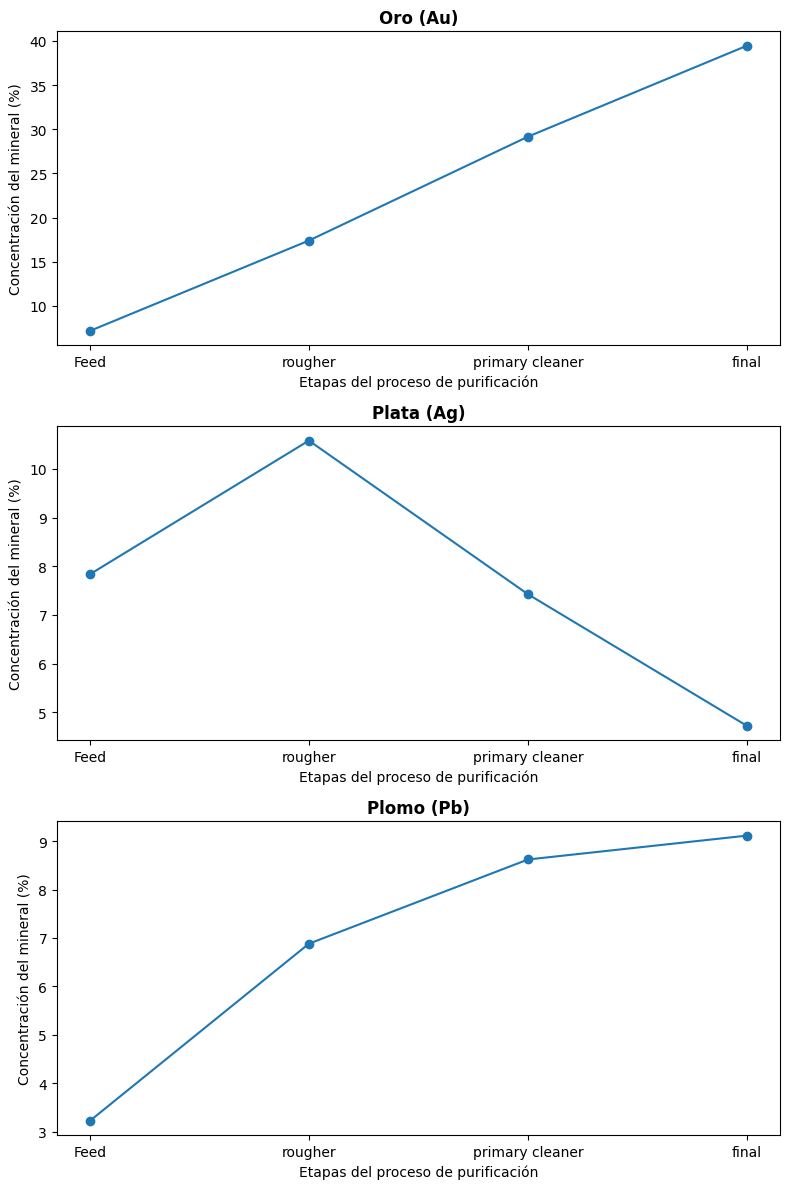

In [6]:

# Función para extraer las columnas de los metales pesados
def concentrate(metal):
    rougher_feed = f"rougher.input.feed_{metal}"
    rougher_output = f"rougher.output.concentrate_{metal}"
    primary_output = f"primary_cleaner.output.concentrate_{metal}"
    final_output = f"final.output.concentrate_{metal}"
    metal_mean = {'Feed': autrain[rougher_feed].mean(), 'rougher': autrain[rougher_output].mean(), 'primary cleaner': autrain[primary_output].mean(), 'final': autrain[final_output].mean()}
    return metal_mean

# Comportamiento Au
au_concentration = concentrate("au")

# Comportamiento Ag
ag_concentration = concentrate("ag")

# Comportamiento Pb
pb_concentration = concentrate("pb")

# Generación de los gráficos de tendencia
metals = [au_concentration, ag_concentration, pb_concentration]
titles = ['Oro (Au)', 'Plata (Ag)', 'Plomo (Pb)']
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8,12))

for i, ax in enumerate(axes):
    stages = list(metals[i].keys())
    concentrations = list(metals[i].values())
    ax.plot(stages, concentrations, marker="o", label=titles[i])
    ax.set_title(titles[i], fontsize=12, fontweight="bold")
    ax.set_ylabel("Concentración del mineral (%)")
    ax.set_xlabel("Etapas del proceso de purificación")
       
plt.tight_layout()
plt.show()


#### Observaciones

Se ha analizado el comportamiento de las concentraciones promedio de los principales metales presentes en el proceso de concentración de oro, los cuales son: oro (Au), plata (Ag) y plomo (Pb).

- El oro presenta un aumento de concentración sostenido en cada etapa de purificación, aumentando mas de 5 veces su concentración desde el alimento hasta su purificación final. Esto demuestra un proceso de extracción eficiente.
- La plata por su parte muestra inicialmente un aumento de su concentración en la etapa Rougher, pero en las purificaciones siguientes su concentración disminuye de forma abrupta. Se revisará en detalle si este mineral se viene concentrando en las colas de proceso, para establecer protocolos de tratamiento de este efluente para su recuperación.
- Finalmente el plomo presenta una concentración en cada etapa de proceso, pero a medida que van pasando las etapas, la concentración empieza a ser mas restringida. Teniendo en cuenta el riesgo de salud que presenta este metal, se hace necesario evaluar su tratamiento.

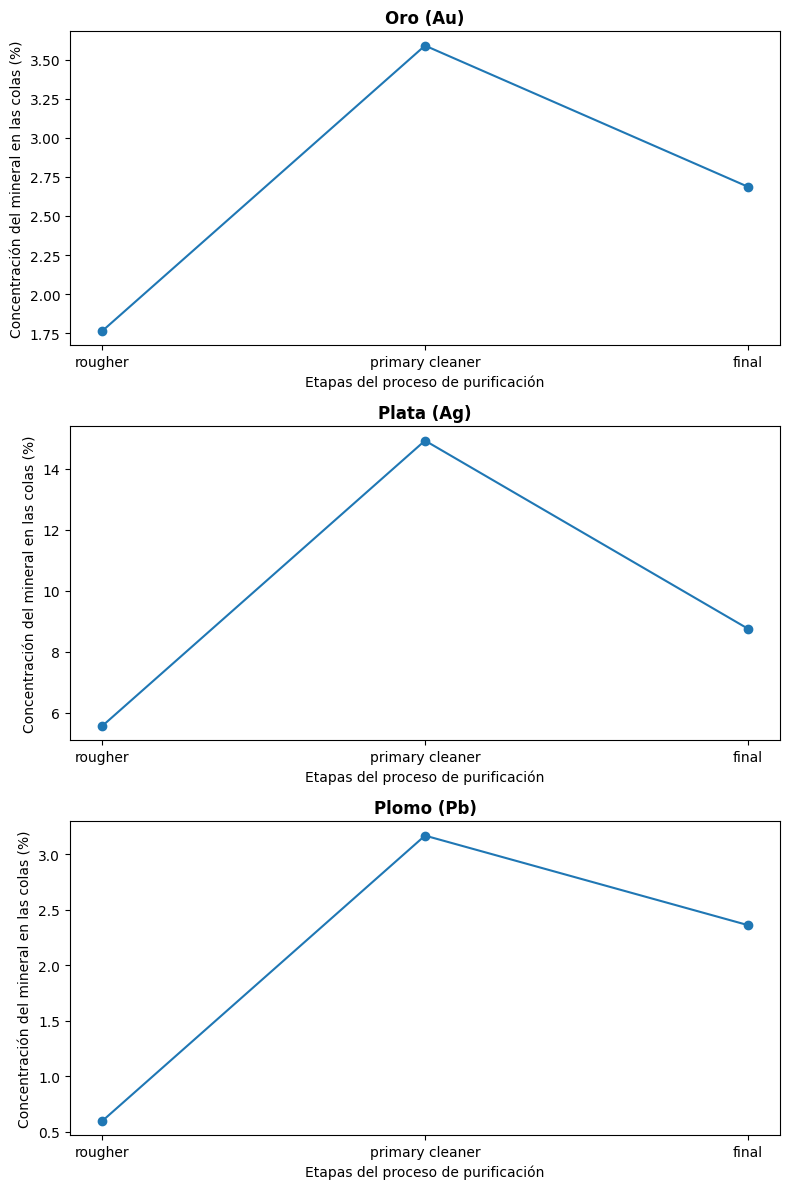

In [7]:

# Función para extraer las columnas de los metales pesados en las colas
def tails(metal):
    rougher_output = f"rougher.output.tail_{metal}"
    primary_output = f"primary_cleaner.output.tail_{metal}"
    final_output = f"final.output.tail_{metal}"
    tail_mean = {'rougher': autrain[rougher_output].mean(), 'primary cleaner': autrain[primary_output].mean(), 'final': autrain[final_output].mean()}
    return tail_mean

# Comportamiento Au
au_tail = tails("au")

# Comportamiento Ag
ag_tail = tails("ag")

# Comportamiento Pb
pb_tail = tails("pb")

# Generación de los gráficos de tendencia
metal_tails = [au_tail, ag_tail, pb_tail]
titles = ['Oro (Au)', 'Plata (Ag)', 'Plomo (Pb)']
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8,12))

for i, ax in enumerate(axes):
    stages = list(metal_tails[i].keys())
    concentration = list(metal_tails[i].values())
    ax.plot(stages, concentration, marker="o", label=titles[i])
    ax.set_title(titles[i], fontsize=12, fontweight="bold")
    ax.set_ylabel("Concentración del mineral en las colas (%)")
    ax.set_xlabel("Etapas del proceso de purificación")
       
plt.tight_layout()
plt.show()


#### Observaciones

Se analiza también el comportamiento de la concentración de los minerales de interés en las colas de proceso, esto es útil para evaluar pérdidas económicas que pueda presentar el proceso en general.

- Se observa en general que la etapa de purificación primaria aumenta la concentración de los 3 metales de interés. Sin embargo, durante la segunda purificación esta concentración vuelve a reducirse.
- Se encuentra que la concentración de plata es la de mayor magnitud en este proceso. esto indica la necesidad de reprocesar este efluente para la recuperación de este mineral tan importante.
- la concentración final de oro y de plomo a la salida de la purificación secundaria es de una magnitud baja pero no despreciable del todo. Esto, junto con la alta concentración de plata hace que se requiera un proceso de tratamiento adicional.

### 2.2 Comparación de la distribución del tamaño de partícula.

count    16443.000000
mean        58.676444
std         23.922591
min          9.659576
25%         47.575879
50%         54.104257
75%         65.051064
max        484.967466
Name: rougher.input.feed_size, dtype: float64

count    5834.000000
mean       55.937535
std        22.724254
min         0.046369
25%        43.890852
50%        50.002004
75%        61.638434
max       477.445473
Name: rougher.input.feed_size, dtype: float64

count    16860.000000
mean         7.297285
std          0.619166
min          1.080000
25%          6.940000
50%          7.285000
75%          7.700000
max         10.470000
Name: primary_cleaner.input.feed_size, dtype: float64

count    5856.000000
mean        7.264651
std         0.611526
min         5.650000
25%         6.885625
50%         7.259333
75%         7.650000
max        15.500000
Name: primary_cleaner.input.feed_size, dtype: float64


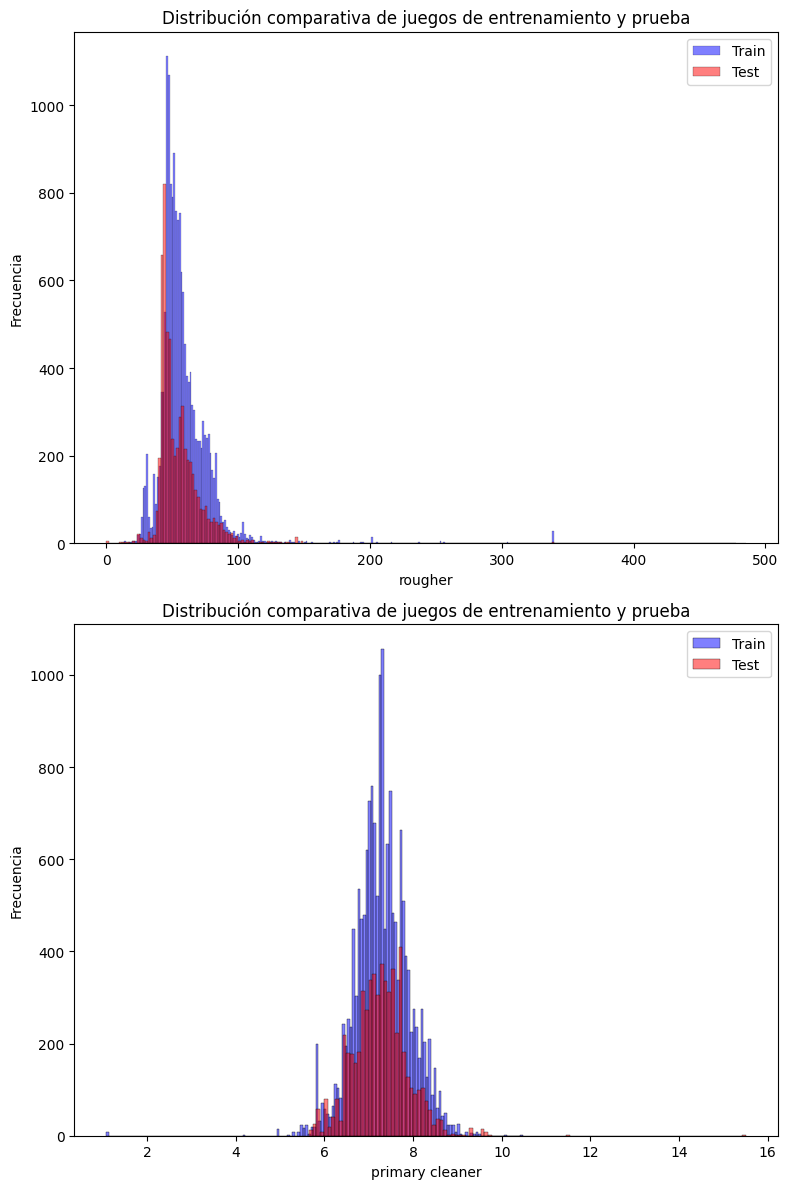

In [8]:

# Obtención variables de tamaño de partícula en sets de entrenamiento y prueba
rougher_size_train = autrain['rougher.input.feed_size']
rougher_size_test = autest['rougher.input.feed_size']
primary_size_train = autrain['primary_cleaner.input.feed_size']
primary_size_test = autest['primary_cleaner.input.feed_size']

size_train = {'rougher': rougher_size_train, 'primary cleaner': primary_size_train}
size_test = {'rougher': rougher_size_test, 'primary cleaner': primary_size_test}

# Estadísticas para estos juegos de datos:
print(size_train['rougher'].describe())
print()
print(size_test['rougher'].describe())
print()
print(size_train['primary cleaner'].describe())
print()
print(size_test['primary cleaner'].describe())

# Configuración de etapas a iterar
stages = ['rougher', 'primary cleaner']

# Creación de las gráficas de distribución
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(8,12))
import seaborn as sns 
# Ciclo de iteración para graficar los histogramas
for i, var in enumerate(stages):
    ax = axes[i]
    # Primer histograma
    sns.histplot(data=size_train, x=var, color='blue', label='Train', alpha=0.5, ax=ax, stat='count')
    # Segundo histograma
    sns.histplot(data=size_test, x=var, color='red', label='Test', alpha=0.5, ax=ax, stat='count')

    ax.set_title('Distribución comparativa de juegos de entrenamiento y prueba')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

#### Observaciones

Se realizan los gráficos de distribución de tamaño de partícula para los sets de entrenamiento y prueba. Se obtuvieron gráficas para las 2 etapas donde se disponen datos de estos tamaños de partícula, la etapa rougher y la primer etapa de purificación. Se incluye también datos estadísticos básicos para los valores analizados.

En general, en ambas etapas, ambos juegos de datos tienen distribuciones similares, teniendo en cuenta que el juego de datos de prueba dispone de un tercio de los datos disponibles para el juego de entrenamiento.

Los valores medios y las desviaciones estándar difieren un poco para la etapa rougher, mientras son muy parecidos en la primera limpieza. Sin embargo, considero que esta pequeña desviación no afecta el entrenamiento de los modelos.

Esto permite suponer que al momento de entrenar los modelos, se tendrá un resultado confiable.

### 2.3 Análisis de concentraciones totales

50.91413738143498
count    16452.000000
mean        50.914137
std         17.877558
min          0.000000
25%         50.736026
50%         55.964544
75%         60.395117
max         76.024095
dtype: float64

60.305417876590354
count    16698.000000
mean        60.305418
std         23.769447
min          0.000000
25%         61.762077
50%         68.406324
75%         73.071456
max         90.964431
dtype: float64

61.524690143117276
count    16489.000000
mean        61.524690
std         21.572949
min          0.000000
25%         66.783177
50%         68.861974
75%         70.753085
max         80.210644
dtype: float64


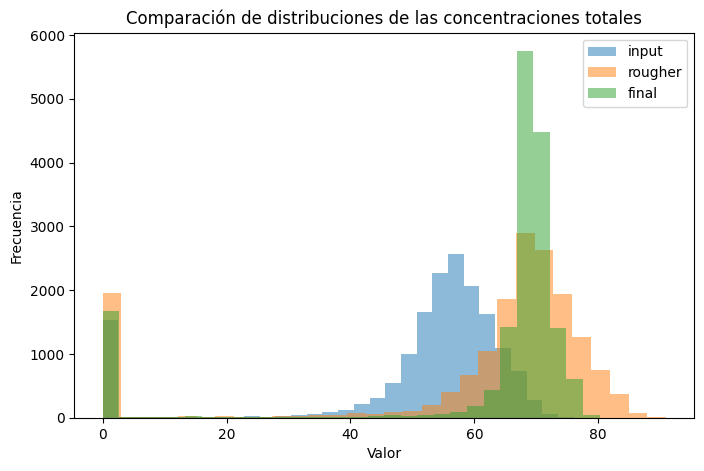

In [9]:

# Función para extraer las columnas de los componentes en las etapas de proceso
def total_concentration(stage):
    au_conc = f"{stage}_au"
    ag_conc = f"{stage}_ag"
    pb_conc = f"{stage}_pb"
    sol_conc = f"{stage}_sol"
    final_conc = autrain[au_conc] + autrain[ag_conc] + autrain[pb_conc] + autrain[sol_conc]
    return final_conc

# Aplicación para materia prima
input_conc = total_concentration('rougher.input.feed')
print(input_conc.mean())
print(input_conc.describe())
print()

# Aplicación para salida etapa rougher
rougher_conc = total_concentration('rougher.output.concentrate')
print(rougher_conc.mean())
print(rougher_conc.describe())
print()

# Aplicación para salida final
final_conc = total_concentration('final.output.concentrate')
print(final_conc.mean())
print(final_conc.describe())

# Gráfico de distribuciones
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(input_conc, bins=30, alpha=0.5, label='input')
ax.hist(rougher_conc, bins=30, alpha=0.5, label='rougher')
ax.hist(final_conc, bins=30, alpha=0.5, label='final')
ax.set_title('Comparación de distribuciones de las concentraciones totales')
ax.set_xlabel('Valor')
ax.set_ylabel('Frecuencia')
ax.legend()

plt.show()


#### Observaciones
Al realizar la revisión de las concentraciones totales en las etapas de alimento, salida etapa rougher y salida de la purificación, se observan anomalías en la distribución de los datos.

La principal anomalía es la presencia de valores de concentración total igual a 0, situación que no tiene coherencia física con el procesos desarrollado. Esto puede deberse a problemas en la medición de valores o situaciones con los sensores.

In [10]:


# Determinación de valores de concentración iguales a cero
zero_input = (input_conc == 0).sum()
zero_rougher = (rougher_conc == 0).sum()
zero_final = (final_conc == 0).sum()
print(f'Concentraciones iguales a cero en la materia prima: ', zero_input)
print()
print(f'Concentraciones iguales a cero en etapa rougher: ', zero_rougher)
print()
print(f'Concentraciones iguales a cero en la salida final: ', zero_final)

# Revisión de las concentraciones de los metales donde la concentración total es igual a 0
print(autrain[input_conc == 0][['rougher.input.feed_au', 'rougher.input.feed_ag', 'rougher.input.feed_pb', 'rougher.input.feed_sol']].head())
print(autrain[rougher_conc == 0][['rougher.output.concentrate_au', 'rougher.output.concentrate_ag', 'rougher.output.concentrate_pb', 'rougher.output.concentrate_sol']].head())
print(autrain[final_conc == 0][['final.output.concentrate_au', 'final.output.concentrate_ag', 'final.output.concentrate_pb', 'final.output.concentrate_sol']].head())




Concentraciones iguales a cero en la materia prima:  1159

Concentraciones iguales a cero en etapa rougher:  1493

Concentraciones iguales a cero en la salida final:  1263
     rougher.input.feed_au  rougher.input.feed_ag  rougher.input.feed_pb  \
99                     0.0                    0.0                    0.0   
100                    0.0                    0.0                    0.0   
101                    0.0                    0.0                    0.0   
102                    0.0                    0.0                    0.0   
103                    0.0                    0.0                    0.0   

     rougher.input.feed_sol  
99                      0.0  
100                     0.0  
101                     0.0  
102                     0.0  
103                     0.0  
    rougher.output.concentrate_au  rougher.output.concentrate_ag  \
45                            0.0                            0.0   
46                            0.0                      

#### Observaciones

Se revisan los datos donde las concentraciones totales en las etapas de entrada, salida del Rougher y salida de la purificación, en total se tienen 3915 datos donde las concentraciones totales son 0.

Adicionalmente se ha revisado como es el estado de las concentraciones individuales de los metales en los puntos donde la concentración total es cero. se encontró que en dichos puntos la concentración de todos los metales involucrados también era igual a cero, esto indica:
- Definitivamente pueden ser datos donde el proceso estaba detenido.
- Son datos donde por alguna situación ajena no se registraron datos.

Por ello, es mejor realizar la eliminación de dichos datos del juego de datos a entrenar.

In [11]:
# Eliminación de filas donde las concentraciones son cero
anomaly_data = (input_conc == 0) | (rougher_conc == 0) | (final_conc == 0)

autrain_clean_filtered = autrain_clean[~anomaly_data.loc[autrain_clean.index]]
print(autrain_clean_filtered)



                     date  primary_cleaner.input.sulfate  \
0     2016-01-15 00:00:00                     127.092003   
1     2016-01-15 01:00:00                     125.629232   
2     2016-01-15 02:00:00                     123.819808   
3     2016-01-15 03:00:00                     122.270188   
4     2016-01-15 04:00:00                     117.988169   
...                   ...                            ...   
16855 2018-08-18 06:59:59                     123.381787   
16856 2018-08-18 07:59:59                     120.878188   
16857 2018-08-18 08:59:59                     105.666118   
16858 2018-08-18 09:59:59                      98.880538   
16859 2018-08-18 10:59:59                      95.248427   

       primary_cleaner.input.depressant  primary_cleaner.input.feed_size  \
0                             10.128295                             7.25   
1                             10.296251                             7.25   
2                             11.316280            

#### Observaciones

Se ha limpiado el juego de datos autrain_clean de los datos donde las concentraciones totales sean iguales a cero para evitar que haya un sesgo indeseado en el entrenamiento de los modelos. 

Se debe realizar un procedimiento similar en el archivo autest_clean para evitar problemas al testear el mejor modelo obtenido.

59.836856502049734
count    5383.000000
mean       59.836857
std         8.295643
min         0.000000
25%        56.380653
50%        59.939028
75%        65.136667
max        76.978947
dtype: float64



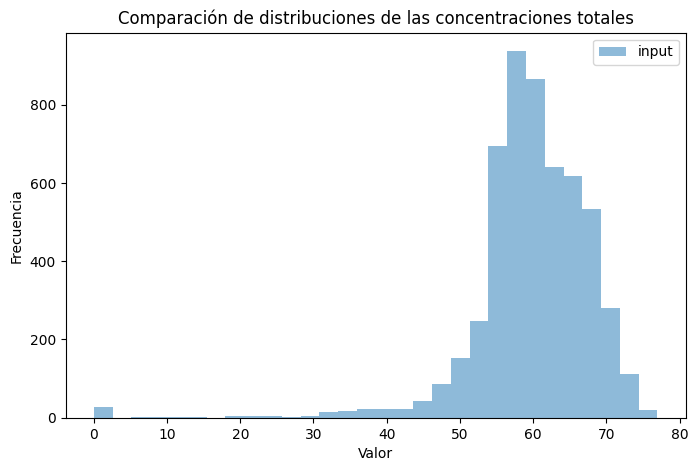

Concentraciones iguales a cero en archivo de prueba:  26

     rougher.input.feed_au  rougher.input.feed_ag  rougher.input.feed_pb  \
169                    0.0                    0.0                    0.0   
170                    0.0                    0.0                    0.0   
171                    0.0                    0.0                    0.0   
493                    0.0                    0.0                    0.0   
664                    0.0                    0.0                    0.0   

     rougher.input.feed_sol  
169                     0.0  
170                     0.0  
171                     0.0  
493                     0.0  
664                     0.0  
                    date  primary_cleaner.input.sulfate  \
0    2016-09-01 00:59:59                     210.800909   
1    2016-09-01 01:59:59                     215.392455   
2    2016-09-01 02:59:59                     215.259946   
3    2016-09-01 03:59:59                     215.336236   
4    2016-

In [12]:
# Archivio autest_clean
final_conc_test = autest_clean['rougher.input.feed_au'] + autest_clean['rougher.input.feed_ag'] + autest_clean['rougher.input.feed_pb'] + autest_clean['rougher.input.feed_sol']
print(final_conc_test.mean())
print(final_conc_test.describe())
print()

# Gráfico de distribuciones
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(final_conc_test, bins=30, alpha=0.5, label='input')
ax.set_title('Comparación de distribuciones de las concentraciones totales')
ax.set_xlabel('Valor')
ax.set_ylabel('Frecuencia')
ax.legend()

plt.show()

# Determinación de valores de concentración iguales a cero
zero_final = (final_conc_test == 0).sum()
print(f'Concentraciones iguales a cero en archivo de prueba: ', zero_final)
print()

# Revisión de las concentraciones de los metales donde la concentración total es igual a 0
print(autest_clean[final_conc_test == 0][['rougher.input.feed_au', 'rougher.input.feed_ag', 'rougher.input.feed_pb', 'rougher.input.feed_sol']].head())

# Eliminación de filas donde las concentraciones son cero
anomaly_data_test = (final_conc_test == 0)

autest_clean_filtered = autest_clean[~anomaly_data_test.loc[autest_clean.index]]
print(autest_clean_filtered)


#### Observaciones
Se realiza en el juego de datos de prueba un tratamiento similar al ejecutado en el juego de datos de entrenamiento.
- Se revisan si se encuentran valores de concentración total igual a cero.
- Se corrobora que los datos de concentración total igual a cero corresponden a valores de cero de todas las concentraciones de metales en la corriente.
- Se eliminan estos valores para cuando se requiera hacer la prueba una vez se tenga el modelo entrenado.

En este momento ya se cuentan con juegos de datos limpios y aptos para realizar el entrenamiento de los modelos y la prueba final.

## 3. Construcción del modelo

### 3.1 Desarrollo de la función sMAPE

In [13]:

# definición de la función del cálculo de sMAPE
def smape_calculation(y_true, y_pred):
    # Conversión de los valores a arrays de numpy
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Cálculo de sMAPE
    mape_num = abs(y_true - y_pred)
    mape_den = (abs(y_true)+abs(y_pred))/2
    mape = (mape_num/mape_den).sum()
    smape = (1 /len(y_true)) * mape * 100
    return smape

# Función para el cálculo de sMAPE final
def final_smape_calculation(y_true_rougher, y_pred_rougher, y_true_final, y_pred_final):
    #Calculo de smape para cada etapa (rougher y final)
    smape_rougher = smape_calculation(y_true_rougher, y_pred_rougher)
    smape_final = smape_calculation(y_true_final, y_pred_final)
    # Cálculo del smape final
    final_smape = (0.25 * smape_rougher) + (0.75 * smape_final)
    return final_smape


#### Observaciones

Se ha programado y corroborado exitosamente el funcionamiento de la función creada para el cálculo de sMAPE.

Se puede proceder con el entrenamiento del modelo aplicado a autrain_clean_filtered

### 3.2 Entrenamiento de modelos

- Se revisa nuevamente el set de datos disponible para el entrenamiento, dispone basicamente de 13157 datos que incluyen las composiciones de entrada y condiciones de operación de los equipos.
- El proceso opera en 2 etapas grandes definidas, la etapa rougher, y las purificaciones (primaria y secundaria), que en este caso serán tratadas como un proceso unificado de purificación.
- Como son 2 etapas, se requiere el entrenamiento de dos modelos separados, uno para la etapa Rougher, y otro para la etapa Final.
- Se tomará para el entrenamiento el juego de datos autrain_clean_filtered. En este set se debe adicionar desde el juego inicial autrain, conservando los índices, la columna de recuperaciones y para los entrenamientos se debe eliminar la columna de fecha porque no influye realmente en el proceso y puede afectar el entrenamiento.
- Para el modelo sobre la etapa Rougher, la característica objetivo será la recuperación en esta etapa, y para la etapa final será la recuperación en esta etapa.
- - De igual manera, para el entrenamiento de la etapa rougher no se usarán datos de proceso de las etapas de purificación debido a que no inciden directamente en la etapa como tal, y realmente podrían afectar las métricas del modelo entrenado.

In [14]:
# Adición de columnas de recuperación al juego de entrenamiento
autrain_clean_filtered = autrain_clean_filtered.join(autrain.loc[autrain_clean_filtered.index, ['rougher.output.recovery', 'final.output.recovery']])

# Set para el modelo rougher
autrain_rougher = autrain_clean_filtered.dropna(subset=['rougher.output.recovery'])
features_rougher = autrain_rougher.drop(['date', 'rougher.output.recovery', 'final.output.recovery'], axis=1)
features_rougher = features_rougher.loc[:, features_rougher.columns.str.contains('rougher')]
target_rougher = autrain_rougher['rougher.output.recovery']

# Set para el modelo final
autrain_final = autrain_clean_filtered.dropna(subset=['final.output.recovery'])
features_final = autrain_final.drop(['date', 'rougher.output.recovery', 'final.output.recovery'], axis=1)
target_final = autrain_final['final.output.recovery']

print(features_rougher.shape, target_rougher.shape)
print(features_final.shape, target_final.shape)

(12490, 22) (12490,)
(13068, 52) (13068,)


#### Observaciones

Se han definido los juegos de datos para el entrenamiento de ambos modelos, uno para la etapa rougher y otro para la etapa final. Con estos datos se puede proceder a evaluar los modelos.

In [15]:
# Conversión de sMAPE a una métrica de evaluación del modelo, minimizando el error
smape_scorer = make_scorer(smape_calculation, greater_is_better=False)

# Modelos de entrenamiento (linear_regression y random_forest)
models = {'Regresión lineal': LinearRegression(), 'Bosque Aleatorio': RandomForestRegressor(n_estimators=50, random_state=792604)}

# Entrenamiento de los modelos con validación cruzada
results_rougher = {}
results_final = {}
for name, model in models.items():
    # Etapa Rougher 
    scores_rougher = cross_val_score(model, features_rougher, target_rougher, cv=5, scoring=smape_scorer)
    score_rougher = -1 * scores_rougher
    smape_rougher = score_rougher.mean()
    results_rougher[name] = smape_rougher

    # Etapa Final 
    scores_final = cross_val_score(model, features_final, target_final, cv=5, scoring=smape_scorer)
    score_final = -1 * scores_final
    smape_final = score_final.mean()
    results_final[name] = smape_final
    
# Conversión de los sMAPE de cada etapa a series de pandas
serie_rougher = pd.Series(results_rougher)
serie_final = pd.Series(results_final)

# Selección del mejor modelo para cada etapa
best_rougher = serie_rougher.idxmin()
best_rougher_smape = serie_rougher.min()
best_final = serie_final.idxmin()
best_final_smape = serie_final.min()

# Cálculo del sMAPE Final
final_smape = (0.25 * best_rougher_smape) + (0.75 * best_final_smape)

#Avisos finales
print('El mejor modelo que describe la etapa rougher es:')
print(best_rougher)
print('')
print('El mejor modelo que describe la etapa final es:')
print(best_final)
print('')
print(f'El sMAPE final óptimo es de: {final_smape:.2f}%')

El mejor modelo que describe la etapa rougher es:
Regresión lineal

El mejor modelo que describe la etapa final es:
Bosque Aleatorio

El sMAPE final óptimo es de: 8.89%


#### Observaciones
- Se realiza entrenamiento de modelos de regresión lineal y bosque aleatorio con 50 árbpoles para esta etapa. Se toman solo estos 2 modelos por ser los de mayor robustez para el manejo de muchos datos y muchas variables de los que se han cubierto en nuestro desarrollo del bootcamp.
- En el bosque se toman solo 50 arboles para reducir el tiempo de computo. Realmente sería interesante probar los mejores hiperparámetros del bosque para determinar las condiciones óptimas pero esto requiere un código mas grande y considero que con 50 árboles queda cubierto el tema de un posible sobredimensionamiento.
- Se encuentra que para la etapa rougher el modelo de regresión líneal arroja el menor sMAPE de los 2 modelos analizados.
- Para la etapa de purificación por su parte, el modelo de bosque aleatorio describe mejor el comportamiento de predicción de recuperaciones.
- Con base en estos resultados se puede desarrollar el modelo para la predicción de los datos en el archivo autest_clean_filtered

### 3.3 Aplicación del modelo en el archivo de prueba

Con base en lo obtenido hasta ahora, se aplicará el modelo de regresión líneal para predecir la recuperación en la etapa rougher y el bosque aleatorio con 50 árboles para predecir las recuperaciones en la etapa final.
Se usará la columna de fecha para obtener las recuperaciones en el archivo de prueba en ambas etapas.

In [16]:
# Conversión de la columna 'date' de aufull a tipo datetime para que se tenga uniformidad de concepto
aufull['date']= pd.to_datetime(aufull['date'])

# Selección de columnas de recuperación de aufull
aufull_recovery = aufull[['date', 'rougher.output.recovery', 'final.output.recovery']]

# Unión de parámetros de recuperación de etapas rougher y purificación en autest_clean_filtered, a partir de los datos de fecha de aufull con merge
autest_clean_filtered = pd.merge(autest_clean_filtered, aufull_recovery, on='date', how='left')

# Creación de juego de datos para la etapa Rougher 
autest_rougher_ready = autest_clean_filtered.dropna(subset=['rougher.output.recovery'])
features_test_rougher = autest_rougher_ready.drop(['date', 'rougher.output.recovery', 'final.output.recovery'], axis=1)
features_test_rougher = features_test_rougher.loc[:, features_test_rougher.columns.str.contains('rougher')]
target_test_rougher = autest_rougher_ready['rougher.output.recovery']

# Creación de juego de datos para la etapa Final 
autest_final_ready = autest_clean_filtered.dropna(subset=['final.output.recovery'])
features_test_final = autest_final_ready.drop(['date', 'rougher.output.recovery', 'final.output.recovery'], axis=1)
target_test_final = autest_final_ready['final.output.recovery']

# Entrenamiento de los modelos
best_model_rougher = LinearRegression()
best_model_rougher.fit(features_rougher, target_rougher)
best_model_final = RandomForestRegressor(n_estimators=50, random_state=792604)
best_model_final.fit(features_final, target_final)

# Predicciones a partir de los modelos
predictions_test_rougher = best_model_rougher.predict(features_test_rougher)
predictions_test_final = best_model_final.predict(features_test_final)

# Cálculo de sMAPE para ambos modelos y sMAPE final
smape_test_rougher = smape_calculation(target_test_rougher, predictions_test_rougher)
smape_test_final = smape_calculation(target_test_final, predictions_test_final)

test_final_smape = (0.25 * smape_test_rougher) + (0.75 * smape_test_final)

print('Resultados finales:')
print(f'sMAPE Etapa Rougher en archivo de prueba: {smape_test_rougher:.2f}%')
print(f'sMAPE Etapa Final en archivo de prueba: {smape_test_final:.2f}%')
print(f'sMAPE FINAL en archivo de prueba: {test_final_smape:.2f}%')

Resultados finales:
sMAPE Etapa Rougher en archivo de prueba: 8.16%
sMAPE Etapa Final en archivo de prueba: 10.25%
sMAPE FINAL en archivo de prueba: 9.73%


#### Observaciones

A partir de los modelos obtenidos previamente, se realiza el entrenamiento del modelo con el archivo de entrenamiento y se corroboran los resultados con el archivo de prueba, el cual se acondiciona previamente para tener valores de comparación.

Se obtiene un sMAPE final de 9.73% que si bien es mas alto que el obtenido durante la valoración cruzada, se debe tener en cuenta que para ello se tuvieron muchos mas datos disponibles que reducen el porcentaje de error.

Sin embargo, los sMAPES calculados, tanto para cada etapa como para el proceso general, mantienen las magnitudes manejadas en la etapa de valoración de los modelos.

## Conclusiones finales
1. Se realiza el tratamiento de datos de un archivo de proceso de extracción y purificación de oro de acuerdo a sus etapas más relevantes.
2. Para cada etapa se realiza la evaluación de 2 modelos de predicción de la recuperación del mineral de interés y se utiliza una métrica específica de proceso para evaluar la validez de los resultados.
3. Se obtuvo que para la etapa Rougher, la cual involucra menos variables en general, el modelo de regresión lineal presenta un buen ajuste con un bajo coste de computo.
4. Para la etapa de recuperación, el modelo que mejor se comporta es el modelo de bosque aleatorio, que si bien consume alto tiempo de computo, produce mejores resultados que el modelo de regresión.
5. Ambos modelos se evaluan posteriormente con los datos del juego de prueba, los cuales siguen una correspondencia, en sus resultados. Esto indica la reproducibilidad del modelo a nuevos juegos de datos.
6. Será interesante probar modelos adicionales que tengan mejor performance a bajo coste de computo y evaluar con mas datos disponibles, así como realizar un estudio de sensibilidad para los hiperparámetros en el modelo de bosque aleatorio para encontrar un modelo robusto para todo el proceso.